In [ ]:
# =========================
# 1) Imports
# =========================
import re
import joblib
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler,
    RobustScaler,
    MinMaxScaler,
    PowerTransformer,
    QuantileTransformer,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, accuracy_score, f1_score


In [ ]:
# =========================
# 2) Google Drive mount
# =========================
from google.colab import drive
drive.mount('/content/drive')

# Edit this path to your file in Drive
xlsx_path = "/content/drive/MyDrive/koi/koifiltered.xlsx"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# =========================
# 3) Full preprocessing and scaler comparison
# =========================

# Config
label_col = "koi_pdisposition"
keep_asymmetric = False       # True keeps separate rel_err_upper and rel_err_lower
min_den = 1e-12               # epsilon to avoid divide by zero in relative error
random_state = 42
test_size = 0.3

# Load
df = pd.read_excel(xlsx_path)
print("Raw shape:", df.shape)

# Function to convert *_err1 and *_err2 into relative error features
def add_uncertainty_features(df_in, keep_asymmetric=False, min_den=1e-12):
    df_out = df_in.copy()

    err1_cols = [c for c in df_out.columns if c.endswith("_err1")]
    base_to_errs = {}
    for e1 in err1_cols:
        base = e1[:-5]  # strip "_err1"
        e2 = f"{base}_err2"
        if e2 in df_out.columns:
            base_to_errs[base] = (e1, e2)

    new_cols = {}
    for base, (e1, e2) in base_to_errs.items():
        if base not in df_out.columns:
            continue
        val = pd.to_numeric(df_out[base], errors="coerce")
        err1 = pd.to_numeric(df_out[e1], errors="coerce").abs()
        err2 = pd.to_numeric(df_out[e2], errors="coerce").abs()

        abs_err_mean = (err1 + err2) / 2.0
        rel_err = abs_err_mean / np.maximum(np.abs(val), min_den)
        new_cols[f"{base}_rel_error"] = rel_err

        if keep_asymmetric:
            new_cols[f"{base}_rel_err_upper"] = err1 / np.maximum(np.abs(val), min_den)
            new_cols[f"{base}_rel_err_lower"] = err2 / np.maximum(np.abs(val), min_den)

    for k, v in new_cols.items():
        df_out[k] = v

    # Drop raw error columns
    drop_cols = []
    for base, (e1, e2) in base_to_errs.items():
        drop_cols.extend([e1, e2])
    df_out = df_out.drop(columns=drop_cols, errors="ignore")

    return df_out, sorted(new_cols.keys())

# Build uncertainty features
df_u, added_unc_cols = add_uncertainty_features(df, keep_asymmetric=keep_asymmetric, min_den=min_den)
print("Added uncertainty columns:", len(added_unc_cols))

# Remove rows with missing labels
df_u = df_u.dropna(axis=0, subset=[label_col])

# Split features and labels
y_raw = df_u[label_col].astype(str).values
X_raw = df_u.drop(columns=[label_col]).copy()

# Drop constant or all-NaN feature columns
constant_cols = [c for c in X_raw.columns if X_raw[c].nunique(dropna=True) <= 1]
if constant_cols:
    X_raw = X_raw.drop(columns=constant_cols)
    print("Dropped constant columns:", constant_cols)

# Encode labels
le = LabelEncoder()
y = le.fit_transform(y_raw)
print("Classes:", list(le.classes_))

# Train test split for a final held out check after CV
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=test_size, random_state=random_state, stratify=y
)

# Define imputing step (median) once
imputer = SimpleImputer(strategy="median")

# Define scalers to compare
scalers = {
    "StandardScaler": StandardScaler(),
    "PowerTransformer_YJ": PowerTransformer(method="yeo-johnson", standardize=True),
    "QuantileTransformer_Normal": QuantileTransformer(output_distribution="normal", random_state=random_state),
}

# Define models to compare
models = {
    "LogReg": LogisticRegression(max_iter=2000, random_state=random_state),
}

# Scoring
scoring = {
    "accuracy": make_scorer(accuracy_score),
    "f1_macro": make_scorer(f1_score, average="macro"),
}

# Cross validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

# Collect results
rows = []

for scaler_name, scaler in scalers.items():
    for model_name, model in models.items():
        pipe = Pipeline(steps=[
            ("imputer", imputer),
            ("scaler", scaler),
            ("clf", model),
        ])

        cv_results = cross_validate(
            pipe, X_train, y_train,
            scoring=scoring, cv=cv, n_jobs=-1, return_train_score=False
        )

        rows.append({
            "Scaler": scaler_name,
            "Model": model_name,
            "CV_Accuracy_Mean": np.mean(cv_results["test_accuracy"]),
            "CV_Accuracy_Std": np.std(cv_results["test_accuracy"]),
            "CV_F1Macro_Mean": np.mean(cv_results["test_f1_macro"]),
            "CV_F1Macro_Std": np.std(cv_results["test_f1_macro"]),
        })

results_df = pd.DataFrame(rows).sort_values(
    by=["CV_Accuracy_Mean", "CV_F1Macro_Mean"], ascending=False
).reset_index(drop=True)

print("Cross validated results (sorted):")
display(results_df)

# Pick the best row and refit on full training set
best = results_df.iloc[0]
best_scaler = scalers[best["Scaler"]]
best_model = models[best["Model"]]

best_pipe = Pipeline(steps=[
    ("imputer", imputer),
    ("scaler", best_scaler),
    ("clf", best_model),
])

best_pipe.fit(X_train, y_train)

# Evaluate on held out test set
from sklearn.metrics import classification_report, confusion_matrix
y_pred = best_pipe.predict(X_test)
print("\nHeld out test set performance with best pipeline:")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Save artifacts
joblib.dump(best_pipe, "best_pipeline.joblib")
joblib.dump(le, "label_encoder.joblib")
print("\nSaved: best_pipeline.joblib, label_encoder.joblib")

# Optional: also save the CV table
results_df.to_csv("scaler_model_cv_results.csv", index=False)
print("Saved: scaler_model_cv_results.csv")


Raw shape: (9564, 40)
Added uncertainty columns: 10
Classes: ['CANDIDATE', 'FALSE POSITIVE']
Cross validated results (sorted):


,Scaler,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_F1Macro_Mean,CV_F1Macro_Std
0,PowerTransformer_YJ,LogReg,0.988198,0.002855,0.988197,0.002854
1,QuantileTransformer_Normal,LogReg,0.987899,0.002735,0.987898,0.002734
2,StandardScaler,LogReg,0.909617,0.039573,0.909409,0.039690



Held out test set performance with best pipeline:
[[1406    9]
 [  23 1432]]
                precision    recall  f1-score   support

     CANDIDATE       0.98      0.99      0.99      1415
FALSE POSITIVE       0.99      0.98      0.99      1455

      accuracy                           0.99      2870
     macro avg       0.99      0.99      0.99      2870
  weighted avg       0.99      0.99      0.99      2870


Saved: best_pipeline.joblib, label_encoder.joblib
Saved: scaler_model_cv_results.csv


PermutationExplainer explainer: 501it [01:15,  6.18it/s]
/tmp/ipython-input-509939964.py:63: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


SHAP views for class: CANDIDATE (index 0)


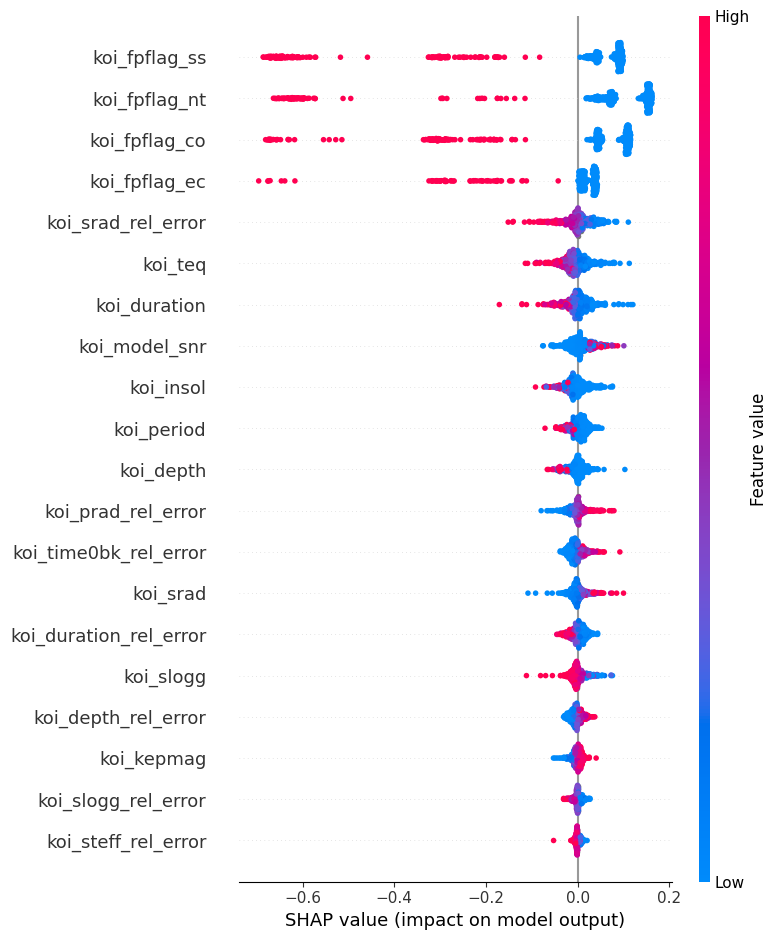

/tmp/ipython-input-509939964.py:71: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


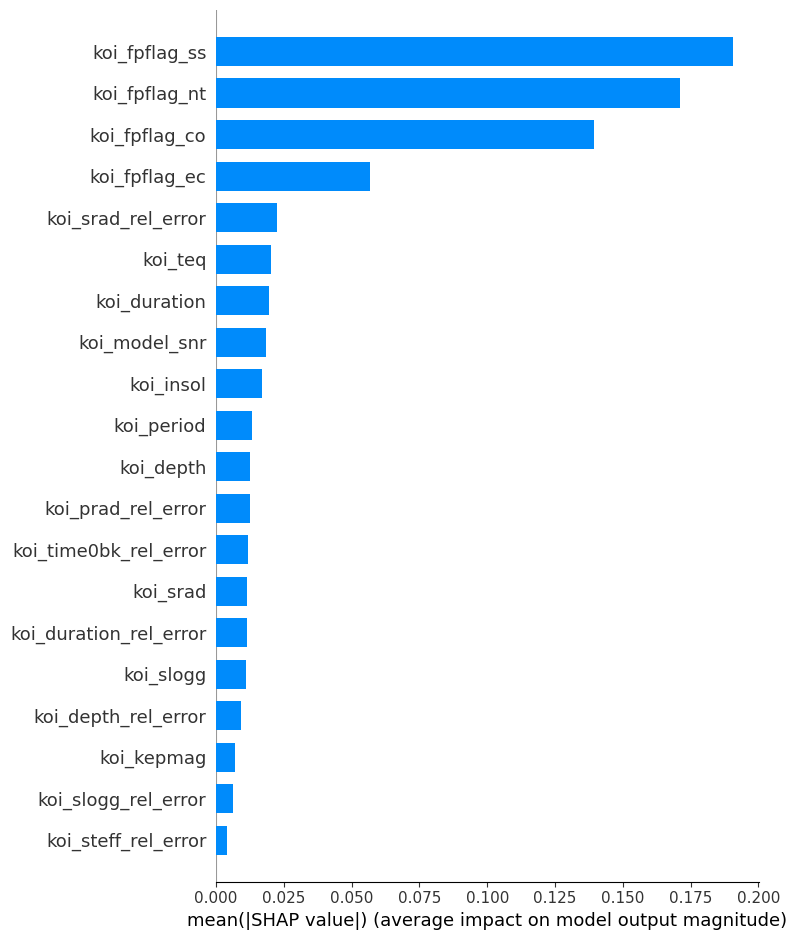


=== SHAP grouped contribution for selected class ===
Flags total: 0.558116  (71.29%)
Non-flags total: 0.224722  (28.71%)

Top 15 features by mean |SHAP|:


,mean|SHAP|
koi_fpflag_ss,0.190681
koi_fpflag_nt,0.171190
koi_fpflag_co,0.139475
koi_fpflag_ec,0.056769
koi_srad_rel_error,0.022444
koi_teq,0.020106
koi_duration,0.019339
koi_model_snr,0.018341
koi_insol,0.016860
koi_period,0.013302



Top 15 features by global mean |SHAP| (across classes):


,global_mean|SHAP|
koi_fpflag_ss,0.190681
koi_fpflag_nt,0.171190
koi_fpflag_co,0.139475
koi_fpflag_ec,0.056769
koi_srad_rel_error,0.022444
koi_teq,0.020106
koi_duration,0.019339
koi_model_snr,0.018341
koi_insol,0.016860
koi_period,0.013302



Flags share of global importance: 71.29%


from matplotlib import pyplot as plt
_df_0['global_mean|SHAP|'].plot(kind='hist', bins=20, title='global_mean|SHAP|')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['global_mean|SHAP|'].plot(kind='line', figsize=(8, 4), title='global_mean|SHAP|')
plt.gca().spines[['top', 'right']].set_visible(False)

In [ ]:
# =========================
# SHAP analysis: feature importance and flags dominance
# Paste this block after the evaluation section
# =========================

# 1) Install and import
!pip -q install shap
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 2) Feature names and background/foreground samples
feature_names = list(X_train.columns)

# Keep SHAP reasonably fast
bg_size = min(200, len(X_train))
fg_size = min(500, len(X_test))

X_bg = X_train.sample(bg_size, random_state=random_state)
X_fg = X_test.sample(fg_size, random_state=random_state)

# 3) A callable that SHAP can query
def proba_fn(data: np.ndarray):
    df_tmp = pd.DataFrame(data, columns=feature_names)
    # predict_proba is available for LogisticRegression and SVC(probability=True)
    if hasattr(best_pipe, "predict_proba"):
        return best_pipe.predict_proba(df_tmp)
    # Fallback to decision_function -> softmax-like conversion
    if hasattr(best_pipe, "decision_function"):
        raw = best_pipe.decision_function(df_tmp)
        raw = np.atleast_2d(raw)
        exp = np.exp(raw - raw.max(axis=1, keepdims=True))
        return exp / exp.sum(axis=1, keepdims=True)
    # Final fallback: one hot on predicted class
    preds = best_pipe.predict(df_tmp)
    n_classes = len(le.classes_)
    one_hot = np.zeros((len(df_tmp), n_classes), dtype=float)
    for i, p in enumerate(preds):
        one_hot[i, p] = 1.0
    return one_hot

# 4) Build explainer (model agnostic)
explainer = shap.Explainer(proba_fn, X_bg, feature_names=feature_names)

# 5) Compute SHAP values for a sample of test data
shap_values = explainer(X_fg)

# 6) Pick a class to visualize
if hasattr(le, "classes_"):
    classes = list(le.classes_)
    target_label = "CONFIRMED" if "CONFIRMED" in classes else classes[0]
    target_idx = classes.index(target_label)
else:
    classes = [f"class_{i}" for i in range(shap_values.values.shape[-1])]
    target_idx = 0
    target_label = classes[target_idx]

print(f"SHAP views for class: {target_label} (index {target_idx})")

# 7) SHAP summary plots for the selected class
# Beeswarm
shap.summary_plot(
    shap_values.values[..., target_idx],
    X_fg,
    feature_names=feature_names,
    show=True
)

# Bar chart
shap.summary_plot(
    shap_values.values[..., target_idx],
    X_fg,
    feature_names=feature_names,
    plot_type="bar",
    show=True
)

# 8) Quantify how much the flag-like features contribute as a group
flag_like_cols = [c for c in feature_names if c.startswith("koi_fpflag_")]
leak_like_cols = set(flag_like_cols + ["koi_disposition", "koi_score"])

mean_abs_shap = np.mean(np.abs(shap_values.values[..., target_idx]), axis=0)
contrib = pd.Series(mean_abs_shap, index=feature_names).sort_values(ascending=False)

flag_total = contrib[contrib.index.isin(leak_like_cols)].sum()
nonflag_total = contrib[~contrib.index.isin(leak_like_cols)].sum()
overall_total = contrib.sum() if contrib.sum() > 0 else 1.0

print("\n=== SHAP grouped contribution for selected class ===")
print(f"Flags total: {flag_total:.6f}  ({100.0 * flag_total / overall_total:.2f}%)")
print(f"Non-flags total: {nonflag_total:.6f}  ({100.0 * nonflag_total / overall_total:.2f}%)")
print("\nTop 15 features by mean |SHAP|:")
display(contrib.head(15).to_frame("mean|SHAP|"))

# 9) Optional: global importance averaged over classes
if shap_values.values.ndim == 3 and shap_values.values.shape[-1] > 1:
    mean_abs_per_class = np.mean(np.abs(shap_values.values), axis=0)  # [n_features, n_classes]
    global_importance = pd.Series(
        mean_abs_per_class.mean(axis=1), index=feature_names
    ).sort_values(ascending=False)

    print("\nTop 15 features by global mean |SHAP| (across classes):")
    display(global_importance.head(15).to_frame("global_mean|SHAP|"))

    flag_total_global = global_importance[global_importance.index.isin(leak_like_cols)].sum()
    global_total = global_importance.sum() if global_importance.sum() > 0 else 1.0
    print(f"\nFlags share of global importance: {100.0 * flag_total_global / global_total:.2f}%")
